<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="figures/cabecalho.jpg" alt="Cabeçalho" style="max-width: 100%; height: auto;">
</div>

# Aplicação de otimização de hiperparâmetros para a predição do índice de refração de materiais inorgânnicos

**Autor**: Carlos Gabriel de Oliveira Campos

Professor Dr. **Daniel Roberto Cassar**

Disciplina de **Aprendizado de Máquina**

Introdução breve (TODO) 

---

### Imports necessários para o notebook

In [1]:
from matminer.datasets import load_dataset
from matminer.featurizers.structure import DensityFeatures
from matminer.featurizers.composition import ElementProperty
from sklearn.linear_model import LinearRegression, ElasticNet, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from optuna.samplers import TPESampler
from functools import partial
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import optuna

### Silenciamento de avisos

In [2]:
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("ignore", category=ConvergenceWarning) # caso lasso não convirja
optuna.logging.set_verbosity(optuna.logging.WARNING) # avisos gerais do optuna

### Importação do dataset

A fonte do dataset utilizado para este trabalho pode ser encontrada em [2], e trata-se de (TODO)

In [3]:
df = pd.read_pickle("dielectric_constant.pkl")
print(f"Quantidade de valores inválidos: {df.isna().sum().sum()}")

Quantidade de valores inválidos: 0


## Estudo da variável alvo

É uma boa prática verificar a distribuição do target que buscamos antes de efetivar os modelos de aprendizado, visto que essa análise pode nos guiar na seleção de métricas para avaliar e comparar os modelos.  

In [4]:
y= df.pop("n")
y.describe()

count    1056.000000
mean        2.434886
std         1.148849
min         1.280000
25%         1.770000
50%         2.190000
75%         2.730000
max        16.030000
Name: n, dtype: float64

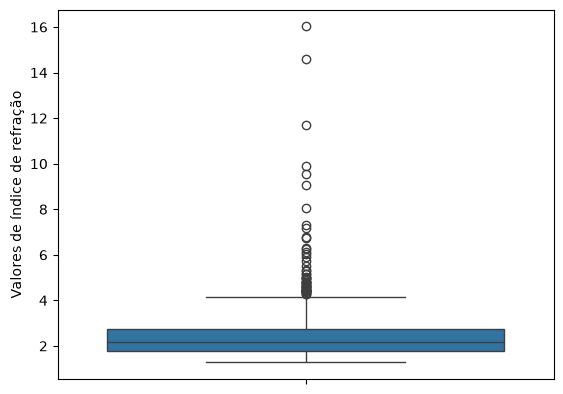

In [5]:
sns.boxplot(y)
plt.ylabel("Valores de índice de refração");

Como é informado pela descrição `y.describe()` e e pelo boxplot, o índice de refração dos materiais 

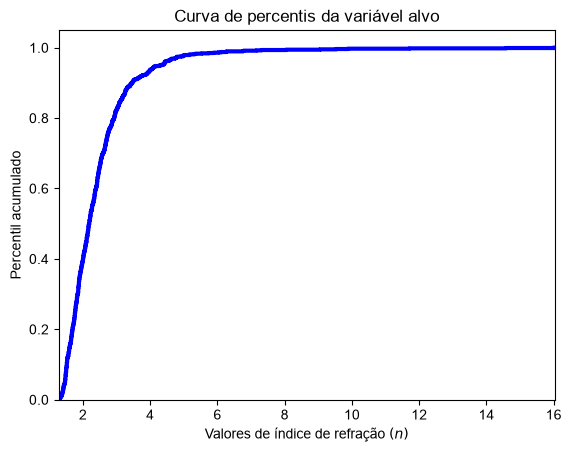

In [6]:
eixo = sns.ecdfplot(data=y, color="blue", linewidth=3)

sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.5})

eixo.set(
    title='Curva de percentis da variável alvo',
    xlabel='Valores de índice de refração $(n)$',
    ylabel='Percentil acumulado',
    xlim=(y.min(), y.max()),
    ylim=(0, 1.05)
);

## Extração de atributos

In [7]:
# 2. Extrair atributos Estruturais (Densidade, volume por átomo, etc.)
dens_feat = DensityFeatures()
labels_dens = dens_feat.feature_labels()
features_dens = [dens_feat.featurize(struct) for struct in df["structure"]]
df_dens = pd.DataFrame(features_dens, columns=labels_dens, index=df.index)

# 3. Extrair atributos Composicionais (Magpie) a partir da estrutura
magpie_feat = ElementProperty.from_preset("magpie")
labels_magpie = magpie_feat.feature_labels()

# Pegamos a composição direto da estrutura (struct.composition)
features_magpie = [magpie_feat.featurize(struct.composition) for struct in df["structure"]]
df_magpie = pd.DataFrame(features_magpie, columns=labels_magpie, index=df.index)

# 4. Unir os dados nativos interessantes com as novas features
X = pd.concat([df, df_dens, df_magpie], axis=1)

### Exclusão de atributos irrelevantes ou causados pelo target

Por exemplo, `structure` é uma matriz de informações a partir da qual outras features são extraídas com as ferramentas do matminer. Já o índice de refração, `n`, está relacionado diretamente com o  target `poly_total`, visto que $n \approx \sqrt{\epsilon}$ (a conferir).

In [8]:
features_excluidas = ["cif", "material_id", "meta", "poscar", "structure", 
    "space_group", "formula", "e_electronic", "e_total", "poly_total", "poly_electronic"]

X.drop(features_excluidas, axis=1, inplace=True);

### Processamento de coluna categórica

In [9]:
colunas_categoricas = ['pot_ferroelectric']

# Tudo que não estiver na lista acima será considerado numérico
colunas_numericas = [col for col in X.columns if col not in colunas_categoricas]

# 3. Criar o pré-processador dividido em dois caminhos paralelos
preprocessor = ColumnTransformer(
    transformers=[
        # Caminho 1: Padroniza apenas as colunas quantitativas
        ('num', StandardScaler(), colunas_numericas),
            
        # Caminho 2: drop='if_binary' converte o booleano numa única coluna 0 ou 1.
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), colunas_categoricas)
    ]
)

### Divisão treino-teste

In [10]:
TAMANHO_TESTE = 0.2
SEMENTE_ALEATORIA = 42

grupos = df['formula']

# 2. Configurar o separador de grupos
gss = GroupShuffleSplit(
    n_splits=1, 
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA
)

for idx_treino, idx_teste in gss.split(X, y, groups=grupos):
    x_treino = X.iloc[idx_treino]
    x_teste = X.iloc[idx_teste]
    y_treino = y.iloc[idx_treino]
    y_teste = y.iloc[idx_teste]
    
    # Evita data leakage ao dividir pela formula das obs. de treino
    grupos_treino = grupos.iloc[idx_treino]

### Baseline

In [11]:
baseline = DummyRegressor()
baseline.fit(x_treino, y_treino)
base_prev = baseline.predict(x_teste)

base_rmse = root_mean_squared_error(y_teste, base_prev)
base_nrmse = base_rmse / y_treino.std()
base_mae = mean_absolute_error(y_teste, base_prev)
base_r2 = r2_score(y_teste, base_prev)

print(
    "",
    "Resultados Baseline",
    "-" * 30,
    f"RMSE: {base_rmse:.3f}",
    f"NRMSE_σ: {base_nrmse:.3f}",
    f"MAE: {base_mae:.3f}",
    f"R²: {base_r2:.3f}",
    sep='\n'
)


Resultados Baseline
------------------------------
RMSE: 1.028
NRMSE_σ: 0.874
MAE: 0.719
R²: -0.005


### Ridge

#### Instância do modelo

In [12]:
def instancia_ridge(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 0.01, 1_000, log=True)
    }

    modelo = make_pipeline(
        preprocessor,
        VarianceThreshold(threshold=0),
        Ridge(**parametros)
    )

    return modelo

#### Função objetivo

In [13]:
def funcao_objetivo_reg(trial, funcao_instancia, X, y, grupos, num_folds):
    """Função objetivo do optuna."""

    modelo_base = funcao_instancia(trial)

    metricas = []

    gkf = GroupKFold(num_folds)

    for passo, fold in enumerate(gkf.split(X, y, groups=grupos)):

        indice_treino, indice_teste = fold

        X_treino_, X_teste_ = X.iloc[indice_treino], X.iloc[indice_teste]
        y_treino_, y_teste_ = y.iloc[indice_treino], y.iloc[indice_teste]

        modelo = clone(modelo_base)
        modelo.fit(X_treino_, y_treino_)
        
        y_verdadeiro = y_teste_
        y_previsto = modelo.predict(X_teste_)

        RMSE = root_mean_squared_error(y_verdadeiro, y_previsto)

        metricas.append(RMSE)
        trial.report(np.mean(metricas), passo)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(metricas)

#### Aplicação do Optuna

In [14]:
NUM_TENTATIVAS = 100
NOME_DO_ESTUDO = "ridge_poda"

NUM_TRIALS_AQUECIMENTO = 5
NUM_PASSOS_AQUECIMENTO = 3

NUM_FOLDS = 5

PODADOR = optuna.pruners.MedianPruner(
    n_startup_trials=NUM_TRIALS_AQUECIMENTO,
    n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
)

estudo_ridge = optuna.create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///optuna_files/{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
    pruner=PODADOR,
)

parcial_ridge = partial(
    funcao_objetivo_reg,
    funcao_instancia=instancia_ridge,
    X=x_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

estudo_ridge.optimize(parcial_ridge, n_trials=NUM_TENTATIVAS);

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(


In [15]:
melhor_trial = estudo_ridge.best_trial

ridge = instancia_ridge(melhor_trial)
ridge.fit(x_treino, y_treino)

ridge_prev = ridge.predict(x_teste)

ridge_rmse = root_mean_squared_error(y_teste, ridge_prev)
ridge_nrmse = ridge_rmse / y_treino.std()
ridge_mae = mean_absolute_error(y_teste, ridge_prev)
ridge_r2 = r2_score(y_teste, ridge_prev)

print(
    "\nResultados do Melhor Modelo de Ridge",
    "-" * 30,
    f"Número do melhor trial: {melhor_trial.number}",
    f"Alpha: {melhor_trial.params['alpha']:.3f}",
    f"RMSE: {ridge_rmse:.3f}",
    f"NRMSE_σ: {ridge_nrmse:.3f}",
    f"MAE: {ridge_mae:.3f}",
    f"R²: {ridge_r2:.3f}",
    sep='\n'
)


Resultados do Melhor Modelo de Ridge
------------------------------
Número do melhor trial: 47
Alpha: 999.305
RMSE: 0.661
NRMSE_σ: 0.561
MAE: 0.333
R²: 0.585


### Lasso

#### Instância do modelo

In [16]:
def instancia_lasso(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 0.01, 1_000, log=True),
        # argumento fixo
        "max_iter": 10_000
    }        

    modelo = make_pipeline(
        preprocessor,
        VarianceThreshold(threshold=0),
        Lasso(**parametros)
    )

    return modelo

In [17]:
NUM_TENTATIVAS = 100
NOME_DO_ESTUDO = "lasso_poda"

NUM_TRIALS_AQUECIMENTO = 5
NUM_PASSOS_AQUECIMENTO = 3

NUM_FOLDS = 5

PODADOR = optuna.pruners.MedianPruner(
    n_startup_trials=NUM_TRIALS_AQUECIMENTO,
    n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
)

estudo_lasso = optuna.create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///optuna_files/{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
    pruner=PODADOR,
)

parcial_lasso = partial(
    funcao_objetivo_reg,
    funcao_instancia=instancia_lasso,
    X=x_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

estudo_lasso.optimize(parcial_lasso, n_trials=NUM_TENTATIVAS)

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(


In [18]:
melhor_trial = estudo_lasso.best_trial

lasso = instancia_lasso(melhor_trial)
lasso.fit(x_treino, y_treino)

lasso_prev = lasso.predict(x_teste)

lasso_rmse = root_mean_squared_error(y_teste, lasso_prev)
lasso_nrmse = lasso_rmse / y_treino.std()
ridge_mae = mean_absolute_error(y_teste, ridge_prev)
lasso_r2 = r2_score(y_teste, lasso_prev)

print(
    "\nResultados do Melhor Modelo de lasso",
    "-" * 30,
    f"Número do melhor trial: {melhor_trial.number}",
    f"Alpha: {melhor_trial.params['alpha']:.3f}",
    f"Número de coeficientes zerados: {list(lasso.named_steps["lasso"].coef_).count(0)} de {x_treino.shape[1]}",
    f"RMSE: {lasso_rmse:.3f}",
    f"NRMSE_σ: {lasso_nrmse:.3f}",
    f"MAE: {ridge_mae:.3f}",
    f"R²: {lasso_r2:.3f}",
    sep='\n'
)


Resultados do Melhor Modelo de lasso
------------------------------
Número do melhor trial: 78
Alpha: 0.044
Número de coeficientes zerados: 110 de 139
RMSE: 0.634
NRMSE_σ: 0.538
MAE: 0.333
R²: 0.618


### ElasticNet

#### Função de instanciamento 

In [19]:
def instancia_elasticnet(trial):
    parametros = {
        # espaço de busca
        "alpha": trial.suggest_float("alpha", 0.01, 1_000, log=True),
        "l1_ratio": trial.suggest_float("l1_ratio", 0, 1),
        # argumento fixo
        "max_iter": 10_000
    }

    modelo = make_pipeline(
        preprocessor,
        VarianceThreshold(threshold=0),
        ElasticNet(**parametros)
    )

    return modelo

#### Aplicação do Optuna

In [20]:
NUM_TENTATIVAS = 100
NOME_DO_ESTUDO = "elasticnet_poda"

NUM_TRIALS_AQUECIMENTO = 5
NUM_PASSOS_AQUECIMENTO = 3

NUM_FOLDS = 5

PODADOR = optuna.pruners.MedianPruner(
    n_startup_trials=NUM_TRIALS_AQUECIMENTO,
    n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
)

estudo_elasticnet = optuna.create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///optuna_files/{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
    pruner=PODADOR,
)

parcial_elasticnet = partial(
    funcao_objetivo_reg,
    funcao_instancia=instancia_elasticnet,
    X=x_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

estudo_elasticnet.optimize(parcial_elasticnet, n_trials=NUM_TENTATIVAS)

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(


#### Verificando resultados

In [21]:
# Treina o modelo final com os melhores parâmetros
melhor_trial = estudo_elasticnet.best_trial
elasticnet = instancia_elasticnet(melhor_trial)
elasticnet.fit(x_treino, y_treino)

# Previsões e métricas no conjunto de teste
y_verdadeiro = y_teste
y_previsao = elasticnet.predict(x_teste)

RMSE_teste = root_mean_squared_error(y_verdadeiro, y_previsao)
R2_teste = r2_score(y_verdadeiro, y_previsao)

# 1. Extrai o modelo ElasticNet de dentro do Pipeline gerado pelo make_pipeline
modelo_en_final = elasticnet.named_steps['elasticnet']

# 2. Calcula quantas features foram zeradas pela penalidade L1
num_features_totais = len(modelo_en_final.coef_)
num_features_zeradas = np.sum(modelo_en_final.coef_ == 0)
num_features_ativas = num_features_totais - num_features_zeradas
percentual_zerado = (num_features_zeradas / num_features_totais) * 100

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO ELASTICNET",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Alpha    : {melhor_trial.params['alpha']:.3f}",
    f" • L1 Ratio : {melhor_trial.params['l1_ratio']:.3f} (0 = Ridge puro | 1 = Lasso puro)",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.3f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE_teste:.3f}",
    f" • R² (Teste Final)         : {R2_teste:.3f}",
    
    f"\n[ Seleção de Features (Esparsidade) ]",
    f" • Total de features recebidas : {num_features_totais}",
    f" • Features ativas usadas      : {num_features_ativas}",
    f" • Features zeradas (L1)       : {num_features_zeradas} ({percentual_zerado:.1f}% de redução)",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO ELASTICNET
Trial vencedor : #44

[ Hiperparâmetros Otimizados ]
 • Alpha    : 0.056
 • L1 Ratio : 0.783 (0 = Ridge puro | 1 = Lasso puro)

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.792  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.634
 • R² (Teste Final)         : 0.618

[ Seleção de Features (Esparsidade) ]
 • Total de features recebidas : 130
 • Features ativas usadas      : 22
 • Features zeradas (L1)       : 108 (83.1% de redução)



### Floresta Aleatória

#### Função de instanciamento

In [22]:
def instancia_floresta_aleatoria(trial):

    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("num_arvores", 5, 300, log=True),
        "criterion": trial.suggest_categorical("critério", ["squared_error", "absolute_error", "poisson"]),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 20),
        "max_features": trial.suggest_float("num_max_atributos", 0, 1),
        # argumentos fixos
        "n_jobs": -1,
        "bootstrap": True,
        "random_state": SEMENTE_ALEATORIA,
    }

    modelo = make_pipeline(
      preprocessor,
      VarianceThreshold(threshold=0),
      RandomForestRegressor(**parametros)
    )

    return modelo

#### Função objetivo

In [23]:
def funcao_objetivo_floresta(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna."""

    modelo_base = instancia_floresta_aleatoria(trial)

    metricas = []

    gkf = GroupKFold(num_folds)

    for passo, fold in enumerate(gkf.split(X, y, groups=grupos)):

        indice_treino, indice_teste = fold

        X_treino_, X_teste_ = X.iloc[indice_treino], X.iloc[indice_teste]
        y_treino_, y_teste_ = y.iloc[indice_treino], y.iloc[indice_teste]

        modelo = clone(modelo_base)
        modelo.fit(X_treino_, y_treino_)
        
        y_verdadeiro = y_teste_
        y_previsto = modelo.predict(X_teste_)

        RMSE = root_mean_squared_error(y_verdadeiro, y_previsto)

        metricas.append(RMSE)
        trial.report(np.mean(metricas), passo)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(metricas)

#### Aplicação

In [24]:
NUM_TENTATIVAS = 100
NOME_DO_ESTUDO = "floresta_aleatoria_poda"

NUM_TRIALS_AQUECIMENTO = 5
NUM_PASSOS_AQUECIMENTO = 3

NUM_FOLDS = 5

PODADOR = optuna.pruners.MedianPruner(
    n_startup_trials=NUM_TRIALS_AQUECIMENTO,
    n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
)

estudo_floresta_aleatoria = optuna.create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///optuna_files/{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
    pruner=PODADOR,
)

parcial_floresta_aleatoria = partial(
    funcao_objetivo_floresta,
    X=x_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

estudo_floresta_aleatoria.optimize(parcial_floresta_aleatoria, n_trials=NUM_TENTATIVAS)

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(


In [25]:
melhor_trial = estudo_floresta_aleatoria.best_trial

floresta = instancia_floresta_aleatoria(melhor_trial).named_steps["randomforestregressor"]
floresta.fit(x_treino, y_treino)

# Previsões e métricas no conjunto de teste
y_previsao = floresta.predict(x_teste)

RMSE_teste = root_mean_squared_error(y_verdadeiro, y_previsao)
R2_teste = r2_score(y_verdadeiro, y_previsao)

# 1. Extrai o modelo RandomForest de dentro do Pipeline gerado pelo make_pipeline
# O make_pipeline usa o nome da classe todo em minúsculo por padrão
modelo_rf_final = floresta

# 2. Avalia a importância das features
importancias = modelo_rf_final.feature_importances_
num_features_totais = len(importancias)

# Uma feature com importância 0.0 não foi usada em nenhuma quebra
num_features_ativas = np.sum(importancias > 0)
num_features_ignoradas = num_features_totais - num_features_ativas
percentual_ignorado = (num_features_ignoradas / num_features_totais) * 100

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO RANDOM FOREST",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • Número de Árvores      : {melhor_trial.params['num_arvores']}",
    f" • Critério               : {melhor_trial.params['critério']}",
    f" • Min. Exemplos Split    : {melhor_trial.params['min_exemplos_split']}",
    f" • Min. Exemplos Folha    : {melhor_trial.params['min_exemplos_folha']}",
    f" • Max Features (Fração)  : {melhor_trial.params['num_max_atributos']:.3f}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.3f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE_teste:.3f}",
    f" • R² (Teste Final)         : {R2_teste:.3f}",
    
    f"\n[ Uso de Features (Importância) ]",
    f" • Total de features recebidas  : {num_features_totais}",
    f" • Features ativas (usadas)     : {num_features_ativas}",
    f" • Features ignoradas (Imp=0.0) : {num_features_ignoradas} ({percentual_ignorado:.1f}% não participaram)",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO RANDOM FOREST
Trial vencedor : #69

[ Hiperparâmetros Otimizados ]
 • Número de Árvores      : 16
 • Critério               : poisson
 • Min. Exemplos Split    : 7
 • Min. Exemplos Folha    : 5
 • Max Features (Fração)  : 0.423

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.617  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.488
 • R² (Teste Final)         : 0.773

[ Uso de Features (Importância) ]
 • Total de features recebidas  : 139
 • Features ativas (usadas)     : 111
 • Features ignoradas (Imp=0.0) : 28 (20.1% não participaram)



### Support Vector Regressor

#### Função de instanciamento

In [26]:
def instancia_svr(trial):

  parametros_svr = {
    # espaço de busca
    'C': trial.suggest_float('C', 1e-1, 1e3, log=True),
    "epsilon": trial.suggest_float('epsilon', 1e-3, 0.5, log=True),
    "gamma": trial.suggest_float('gamma', 1e-4, 1.0, log=True),
    # arg fixo
    'kernel': 'rbf'
  }
  
  # svr_log = TransformedTargetRegressor(
  #   regressor=svr_base,
  #   func=np.log1p,
  #   inverse_func=np.expm1
  # )
  
  etapas_pipe = [preprocessor, VarianceThreshold(threshold=0)]
  usa_pca = trial.suggest_categorical('usar_pca', [True, False])

  if usa_pca:
    num_componentes_pca = trial.suggest_int('num_componentes', 10, 70)
    etapas_pipe.append(PCA(num_componentes_pca))

  svr = SVR(**parametros_svr)
  etapas_pipe.append(svr)
  
  return make_pipeline(*etapas_pipe)

#### Função objetivo

In [27]:
def funcao_objetivo_svr(trial, X, y, grupos, num_folds):
    """Função objetivo do optuna."""

    modelo_base = instancia_svr(trial)

    metricas = []

    gkf = GroupKFold(num_folds)

    for passo, fold in enumerate(gkf.split(X, y, groups=grupos)):

        indice_treino, indice_teste = fold

        X_treino_, X_teste_ = X.iloc[indice_treino], X.iloc[indice_teste]
        y_treino_, y_teste_ = y.iloc[indice_treino], y.iloc[indice_teste]

        modelo = clone(modelo_base)
        modelo.fit(X_treino_, y_treino_)
        
        y_verdadeiro = y_teste_
        y_previsto = modelo.predict(X_teste_)

        RMSE = root_mean_squared_error(y_verdadeiro, y_previsto)

        metricas.append(RMSE)
        trial.report(np.mean(metricas), passo)

        if trial.should_prune():
            raise optuna.TrialPruned()

    return np.mean(metricas)

#### Aplicação

In [28]:
NUM_TENTATIVAS = 100
NOME_DO_ESTUDO = "svr_poda"

NUM_TRIALS_AQUECIMENTO = 5
NUM_PASSOS_AQUECIMENTO = 3

NUM_FOLDS = 5

PODADOR = optuna.pruners.MedianPruner(
    n_startup_trials=NUM_TRIALS_AQUECIMENTO,
    n_warmup_steps=NUM_PASSOS_AQUECIMENTO,
)

estudo_svr = optuna.create_study(
    direction="minimize",
    study_name=NOME_DO_ESTUDO,
    storage=f"sqlite:///optuna_files/{NOME_DO_ESTUDO}.db",
    load_if_exists=True,
    sampler=TPESampler(multivariate=True),
    pruner=PODADOR,
)

parcial_svr = partial(
    funcao_objetivo_svr,
    X=x_treino,
    y=y_treino,
    grupos=grupos_treino,
    num_folds=NUM_FOLDS
)

estudo_svr.optimize(parcial_svr, n_trials=NUM_TENTATIVAS)

c:\venv\ilumpy\Lib\site-packages\optuna\_experimental.py:32: ExperimentalWarning: Argument ``multivariate`` is an experimental feature. The interface can change in the future.
  warnings.warn(
[W 2026-10-19 07:30:16,379] The parameter `num_componentes` in Trial#104 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sampling` to `False` in the constructor of `TPESampler` if this independent sampling is intended behavior.
[W 2026-10-19 07:30:27,407] The parameter `num_componentes` in Trial#111 is sampled independently using `RandomSampler` instead of `TPESampler`, potentially degrading the optimization performance. This fallback happend because dynamic search space is not supported for `multivariate=True`. You can suppress this warning by setting `warn_independent_sa

In [29]:
######### VISUALIZAÇÃO DE RESULTADOS (Adaptada para SVR)

# 1. Recupera o melhor trial e treina o pipeline completo final
melhor_trial = estudo_svr.best_trial
pipeline_final = instancia_svr(melhor_trial)
pipeline_final.fit(x_treino, y_treino)

# 2. Previsões e métricas no conjunto de teste independente
y_previsao = pipeline_final.predict(x_teste)

y_verdadeiro = y_teste
RMSE_teste = root_mean_squared_error(y_verdadeiro, y_previsao)
MAE_teste = mean_absolute_error(y_verdadeiro, y_previsao)
R2_teste = r2_score(y_verdadeiro, y_previsao)

print(
    f"\n{'='*50}",
    f"🏆 RESULTADOS DO MELHOR MODELO SVR (RBF)",
    f"{'='*50}",
    f"Trial vencedor : #{melhor_trial.number}",
    
    f"\n[ Hiperparâmetros Otimizados ]",
    f" • C (Penalidade)         : {melhor_trial.params['C']:.3f}",
    f" • Epsilon (Tubo)         : {melhor_trial.params['epsilon']:.3f}",
    f" • Gamma (Raio Kernel)    : {melhor_trial.params['gamma']:.3f}",
    f" • Componentes PCA        : {melhor_trial.params.get('num_componentes', '(Sem PCA)')}",
    
    f"\n[ Métricas de Desempenho ]",
    f" • RMSE (Validação Cruzada) : {melhor_trial.value:.3f}  <- Otimizado pelo Optuna",
    f" • RMSE (Teste Final)       : {RMSE_teste:.3f}",
    f" • MAE (Teste Final)       : {MAE_teste:.3f}",
    f" • R² (Teste Final)         : {R2_teste:.3f}",
    f"{'='*50}\n",
    sep="\n"
)


🏆 RESULTADOS DO MELHOR MODELO SVR (RBF)
Trial vencedor : #159

[ Hiperparâmetros Otimizados ]
 • C (Penalidade)         : 76.816
 • Epsilon (Tubo)         : 0.041
 • Gamma (Raio Kernel)    : 0.001
 • Componentes PCA        : (Sem PCA)

[ Métricas de Desempenho ]
 • RMSE (Validação Cruzada) : 0.674  <- Otimizado pelo Optuna
 • RMSE (Teste Final)       : 0.587
 • MAE (Teste Final)       : 0.201
 • R² (Teste Final)         : 0.672



## Conclusão

## Referências

## Uso de IA neste trabalho

<div style="width: 100%; text-align: center; margin-bottom: 20px;">
  <img src="figures/rodape_eleicao.png" alt="Rodapé" style="max-width: 100%; height: auto;">
</div>